# ACA 2 · Aprendizaje Automático
## Alerta temprana de deserción estudiantil con redes neuronales: una GRU que lee la trayectoria semestre a semestre

**Corporación Unificada Nacional de Educación Superior (CUN)** · Escuela de Ingeniería · Especialización en Inteligencia Artificial
**Asignatura:** Aprendizaje Automático · **Docente:** Dr. Hamilton Rivera Flor

**Integrantes (Grupo 7):**
- Bonny Darhyll Brayan Galindo Santos
- Anternol de los Reyes Bedoya Naranjo
- Andrés Alberto López Herrera
- Camilo José Rodríguez Ayubi

**Pilar:** 🎓 Proyecto 2 – Educación · **Dataset:** *Predict Students' Dropout and Academic Success* (UCI Machine Learning Repository, id 697)
**Arquitecturas:** GRU híbrida con embeddings (principal) · MLP profundo · FT-Transformer · línea base: regresión logística del ACA 1

Noviembre de 2026

### Contenido
0. Contexto: del ACA 1 al ACA 2
1. **Paso 1** – Exploración y gestión de los datos en SQL (SQLite)
2. **Paso 2** – Preparación: codificador, secuencias y aumento de datos
3. **Paso 3** – Modelado con redes neuronales (búsqueda de hiperparámetros con validación cruzada)
4. **Paso 4** – Evaluación y métricas en el conjunto de prueba
5. **Paso 5** – Exportación a ONNX para la app de Streamlit
6. Conclusiones y referencias (APA 7)

## 0. Contexto: del ACA 1 al ACA 2

En el ACA 1 el equipo predijo el resultado académico de 4.424 estudiantes (*Deserción*, *Matriculado* o *Graduado*) con modelos clásicos. Ganó una regresión logística: F1 macro de 0,691, exactitud de 74,0 % y ROC-AUC de 0,874 en un conjunto de prueba de 885 estudiantes. Ese trabajo dejó dos hallazgos que guían este:

1. **Lo que pasa en el primer año pesa más que el puntaje de ingreso.** Las unidades aprobadas en S1 y S2 fueron, de lejos, las variables más importantes.
2. **Alertar temprano cuesta precisión.** Con solo los datos de matrícula el F1 caía a 0,560; tras el primer semestre, a 0,655. En el ACA 1 hicieron falta **tres modelos distintos**, uno por etapa.

Ambos hallazgos apuntan a una red recurrente. La trayectoria de un estudiante es una secuencia (matrícula → S1 → S2), y una red recurrente la procesa en ese orden, actualizando una memoria cada semestre. Si además se entrena ocultando al azar los semestres que "todavía no han ocurrido", **un solo modelo** puede dar la alerta en cualquiera de las tres etapas.

**Objetivo general.** Desarrollar e implementar una solución con redes neuronales artificiales (una GRU híbrida con *embeddings*, comparada con un perceptrón multicapa profundo y un Transformer tabular) que estime el riesgo de deserción a partir de datos académicos, demográficos y socioeconómicos, integrando la gestión de los datos en SQL, el preprocesamiento, el entrenamiento, la evaluación y el despliegue en una aplicación interactiva de Streamlit.

**Pregunta orientadora.** ¿Cómo aprovechar las arquitecturas de redes neuronales (CNN, RNN, Transformers) para extraer patrones complejos en datos de educación, optimizando el rendimiento predictivo y permitiendo su interacción práctica a través de una interfaz en Streamlit?

En concreto, este trabajo responde: **¿puede una red recurrente que lee la trayectoria del estudiante igualar o superar a la regresión logística del ACA 1 y, a la vez, servir para alertar desde el día de la matrícula?**

| | ACA 1 | ACA 2 |
|---|---|---|
| Datos | CSV en memoria | Base SQLite normalizada (estudiantes, semestres, cohortes, programas) |
| Representación | One-hot + escalado | *Embeddings* aprendidos + secuencia S1 → S2 + máscara de etapa |
| Modelo | Regresión logística (C = 0,1) | GRU híbrida, MLP profundo y FT-Transformer (PyTorch) |
| Alerta temprana | 3 modelos (uno por etapa) | 1 modelo para las 3 etapas |
| Despliegue | joblib + scikit-learn | Ensamble de 5 redes exportado a ONNX + onnxruntime |

In [1]:
# Librerías y configuración
import os, json, time, subprocess, warnings
from pathlib import Path

# En Google Colab: si no están los módulos del proyecto, se clona el repositorio
if not Path("nucleo").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/BonnyGalindo77/aca2-redes-neuronales-desercion.git", "repo"], check=True)
    os.chdir("repo")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import sklearn
from IPython.display import display, Markdown
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from nucleo import base_datos as bd
from nucleo import codificador as cdf
from nucleo import entrenamiento as en
from nucleo import linea_base as lb
from nucleo import preprocesamiento as pp
from nucleo import redes

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SEED = 42
en.fijar_semilla(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))

CLASES = pp.ORDEN_CLASES                       # ['Deserción', 'Matriculado', 'Graduado']
IDX = {c: i for i, c in enumerate(CLASES)}
COLORES = {"Deserción": "#C0392B", "Matriculado": "#E08A1E", "Graduado": "#1A4F8B"}
COLOR_MODELO = {"GRU híbrida": "#E08A1E", "MLP profundo": "#3F8F3A", "FT-Transformer": "#6C3FA0",
                "Regresión logística (ACA 1)": "#5B6770"}
NOMBRE = {"rnn": "GRU híbrida", "mlp": "MLP profundo", "ftt": "FT-Transformer", "lr": "Regresión logística (ACA 1)"}
ETAPAS = cdf.ETAPAS
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

FIGS = Path("figuras"); FIGS.mkdir(exist_ok=True)
MODELO = Path("modelo"); MODELO.mkdir(exist_ok=True)
RES = Path("resultados"); RES.mkdir(exist_ok=True)
print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

PyTorch 2.15.0+cu132 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


---
## Paso 1 · Exploración y gestión de los datos en SQL

### 1.1 De un CSV plano a una base de datos relacional
El archivo de la UCI trae una fila por estudiante con 37 columnas. Ese formato mezcla tres cosas distintas: los datos del estudiante al ingresar, su desempeño en cada semestre y el contexto económico del año en que entró. El módulo `nucleo/base_datos.py` lo lleva a **SQLite** con este esquema:

| Tabla | Filas | Contenido |
|---|---|---|
| `uci_crudo` | 4.424 | El CSV tal como llega (tabla de preparación) |
| `programas` | 17 | Código y nombre en español de cada programa |
| `cohortes` | 10 | Desempleo, inflación y PIB del año de ingreso (solo hay 10 combinaciones distintas) |
| `estudiantes` | 4.424 | Datos de ingreso y socioeconómicos, resultado y partición entrenamiento/prueba |
| `semestres` | 8.848 | **Trayectoria en formato largo**: una fila por estudiante y semestre |
| `predicciones` | — | Bitácora de las predicciones que se hacen desde la app |

La tabla `semestres` es la pieza clave: de ahí salen, con SQL, las secuencias que lee la red recurrente. Las reglas de limpieza del ACA 1 se aplican con sentencias `UPDATE` dentro de la base, así quedan documentadas junto a los datos.

In [2]:
RUTA_CSV = Path("data/students_dropout.csv")
RUTA_DB = Path("data/desercion.db")
resumen_db = bd.crear_base(RUTA_CSV, RUTA_DB, semilla=SEED)

def sql(consulta, **params):
    return bd.consultar(RUTA_DB, consulta, params)

display(pd.Series(resumen_db["filas"], name="filas cargadas").to_frame())
display(pd.Series(resumen_db["limpieza"], name="filas afectadas").to_frame())

,filas cargadas
uci_crudo,4424
programas,17
cohortes,10
estudiantes,4424
semestres,8848


,filas afectadas
Marcar estudiantes sin registro curricular (0 inscritas en S1 y S2),180
Convertir sus ceros estructurales en NULL,360
Anular promedios < 10 con unidades aprobadas (se aprueba con 10/20),1


Las tres reglas de limpieza heredadas del ACA 1 se cumplen tal cual: los **180 estudiantes de *Animación y diseño multimedia*** que figuran con cero unidades inscritas en ambos semestres (aunque 75 de ellos se graduaron) quedan marcados con `sin_registro_curricular = 1`, y sus 360 registros semestrales pasan a `NULL`. Un promedio inferior a 10 con unidades aprobadas, imposible en la escala portuguesa, también se anula.

In [3]:
objetos = sql("SELECT type AS tipo, name AS nombre FROM sqlite_master "
              "WHERE type IN ('table', 'view') AND name NOT LIKE 'sqlite_%' ORDER BY type, name")
display(objetos)
print(sql("SELECT sql FROM sqlite_master WHERE name = 'semestres'").iloc[0, 0])

,tipo,nombre
0,table,cohortes
1,table,estudiantes
2,table,predicciones
3,table,programas
4,table,semestres
5,table,uci_crudo
6,view,v_estudiantes_plano


CREATE TABLE semestres (
    estudiante_id   INTEGER NOT NULL REFERENCES estudiantes(estudiante_id),
    semestre        INTEGER NOT NULL CHECK (semestre IN (1, 2)),
    convalidadas    REAL,
    inscritas       REAL,
    evaluaciones    REAL,
    aprobadas       REAL,
    nota            REAL,
    sin_evaluacion  REAL,
    PRIMARY KEY (estudiante_id, semestre)
)


### 1.2 Análisis exploratorio con consultas SQL

In [4]:
dist = sql('''
    SELECT resultado, COUNT(*) AS estudiantes,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM estudiantes), 1) AS porcentaje
    FROM estudiantes GROUP BY resultado
''').set_index("resultado").reindex(CLASES)
display(dist)

,estudiantes,porcentaje
resultado,,
Deserción,1421,32.100
Matriculado,794,17.900
Graduado,2209,49.900


La distribución es la misma del ACA 1: 32,1 % deserta, 17,9 % sigue matriculado y 49,9 % se gradúa. *Matriculado* es la clase minoritaria y la más difícil, por eso la métrica principal sigue siendo el **F1 macro**.

**¿Cómo cambia la trayectoria entre semestres?** Esta consulta une `semestres` con `estudiantes` y promedia el desempeño por resultado final y semestre.

aprobadas       tasa_aprobacion       promedio       
semestre            1     2               1     2        1      2
resultado                                                        
Deserción       2.700 2.050           0.410 0.310    7.670  6.240
Matriculado     4.480 4.210           0.710 0.670   11.530 11.520
Graduado        6.450 6.390           0.930 0.930   13.090 13.140

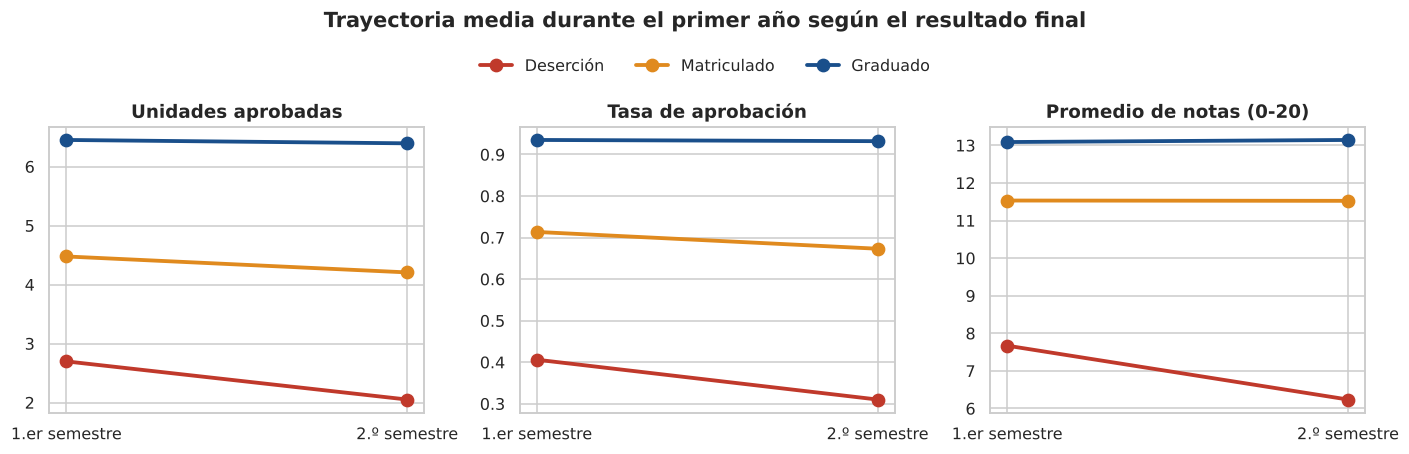

In [5]:
tray = sql('''
    SELECT e.resultado, s.semestre,
           AVG(s.inscritas)  AS inscritas,
           AVG(s.aprobadas)  AS aprobadas,
           AVG(CASE WHEN s.inscritas > 0 THEN 1.0 * s.aprobadas / s.inscritas END) AS tasa_aprobacion,
           AVG(s.nota)       AS promedio
    FROM semestres s JOIN estudiantes e USING (estudiante_id)
    WHERE e.sin_registro_curricular = 0
    GROUP BY e.resultado, s.semestre
''')
display(tray.pivot(index="resultado", columns="semestre",
                   values=["aprobadas", "tasa_aprobacion", "promedio"]).reindex(CLASES).round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (v, t) in zip(axes, [("aprobadas", "Unidades aprobadas"), ("tasa_aprobacion", "Tasa de aprobación"),
                             ("promedio", "Promedio de notas (0-20)")]):
    for c in CLASES:
        d = tray[tray.resultado == c]
        ax.plot(["1.er semestre", "2.º semestre"], d[v], "o-", lw=2.5, ms=8, color=COLORES[c], label=c)
    ax.set_title(t)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.suptitle("Trayectoria media durante el primer año según el resultado final", fontweight="bold", y=1.08)
plt.tight_layout(); plt.savefig(FIGS / "01_trayectorias.png", dpi=200, bbox_inches="tight"); plt.show()

Los graduados mantienen el ritmo de un semestre a otro: aprueban 6,45 y luego 6,39 unidades en promedio, con una tasa de aprobación estable de 0,93. Quienes desertan no solo arrancan más abajo, también caen: pasan de 2,70 a 2,05 unidades aprobadas, de 0,41 a 0,31 en tasa de aprobación y de 7,67 a 6,24 de promedio. Los matriculados quedan en medio y bajan un poco. Lo que distingue a los grupos es el nivel y también la **dirección del cambio**, y esa información solo se ve si se leen S1 y S2 en orden, que es lo que hace una red recurrente.

In [6]:
transiciones = sql('''
    SELECT e.resultado,
           COUNT(*) AS estudiantes,
           ROUND(100.0 * AVG(s2.aprobadas < s1.aprobadas), 1)                  AS pct_aprueba_menos_en_S2,
           ROUND(100.0 * AVG(s1.aprobadas > 0 AND s2.aprobadas = 0), 1)        AS pct_cae_a_cero_en_S2,
           ROUND(100.0 * AVG(s1.aprobadas = 0 AND s2.aprobadas = 0), 1)        AS pct_cero_en_ambos
    FROM estudiantes e
    JOIN semestres s1 ON s1.estudiante_id = e.estudiante_id AND s1.semestre = 1
    JOIN semestres s2 ON s2.estudiante_id = e.estudiante_id AND s2.semestre = 2
    WHERE e.sin_registro_curricular = 0
    GROUP BY e.resultado
''').set_index("resultado").reindex(CLASES)
transiciones

,estudiantes,pct_aprueba_menos_en_S2,pct_cae_a_cero_en_S2,pct_cero_en_ambos
resultado,,,,
Deserción,1344,38.300,13.500,34.900
Matriculado,766,37.500,1.700,3.500
Graduado,2134,17.700,0.000,0.000


Este *self-join* compara a cada estudiante consigo mismo. El 38,3 % de quienes desertan aprueba menos en S2 que en S1, frente al 17,7 % de los graduados. Más revelador aún: el 13,5 % de los desertores pasa de aprobar algo en S1 a no aprobar nada en S2, algo que no hace ningún graduado, y el 34,9 % no aprueba una sola unidad en todo el año. Son patrones de caída, es decir, información secuencial.

In [7]:
programas = sql('''
    SELECT p.nombre AS programa, COUNT(*) AS estudiantes,
           ROUND(100.0 * AVG(e.resultado = 'Deserción'), 1) AS desercion_pct,
           ROUND(100.0 * AVG(e.resultado = 'Graduado'), 1)  AS graduacion_pct,
           RANK() OVER (ORDER BY AVG(e.resultado = 'Deserción') DESC) AS puesto
    FROM estudiantes e JOIN programas p ON p.codigo = e.programa
    GROUP BY p.nombre ORDER BY puesto
''')
factores = sql('''
    SELECT 'Matrícula al día' AS factor, CASE matricula_al_dia WHEN 1 THEN 'Sí' ELSE 'No' END AS valor,
           COUNT(*) AS estudiantes, ROUND(100.0 * AVG(resultado = 'Deserción'), 1) AS desercion_pct
    FROM estudiantes GROUP BY matricula_al_dia
    UNION ALL
    SELECT 'Deudor', CASE deudor WHEN 1 THEN 'Sí' ELSE 'No' END, COUNT(*),
           ROUND(100.0 * AVG(resultado = 'Deserción'), 1) FROM estudiantes GROUP BY deudor
    UNION ALL
    SELECT 'Becado', CASE becado WHEN 1 THEN 'Sí' ELSE 'No' END, COUNT(*),
           ROUND(100.0 * AVG(resultado = 'Deserción'), 1) FROM estudiantes GROUP BY becado
''')
cohortes = sql('''
    SELECT c.cohorte_id, c.tasa_desempleo, c.tasa_inflacion, c.pib, COUNT(*) AS estudiantes,
           ROUND(100.0 * AVG(e.resultado = 'Deserción'), 1) AS desercion_pct
    FROM estudiantes e JOIN cohortes c USING (cohorte_id)
    GROUP BY c.cohorte_id ORDER BY desercion_pct DESC
''')
display(programas.head(6)); display(factores); display(cohortes)

,programa,estudiantes,desercion_pct,graduacion_pct,puesto
0,Tecnologías de producción de biocombustibles,12,66.700,8.300,1
1,Equinocultura,141,55.300,29.800,2
2,Ingeniería informática,170,54.100,8.200,3
3,Administración (nocturno),268,50.700,29.100,4
4,Educación básica,192,44.300,29.700,5
5,Agronomía,210,41.000,41.400,6


,factor,valor,estudiantes,desercion_pct
0,Matrícula al día,No,528,86.600
1,Matrícula al día,Sí,3896,24.700
2,Deudor,No,3921,28.300
3,Deudor,Sí,503,62.000
4,Becado,No,3325,38.700
5,Becado,Sí,1099,12.200


,cohorte_id,tasa_desempleo,tasa_inflacion,pib,estudiantes,desercion_pct
0,10,16.200,0.300,-0.920,362,38.400
1,1,7.600,2.600,0.320,571,35.400
2,9,15.500,2.800,-4.060,397,35.000
3,4,10.800,1.400,1.740,525,34.700
4,7,12.700,3.700,-1.700,419,33.700
5,3,9.400,-0.800,-3.120,533,32.600
6,8,13.900,-0.300,0.790,390,30.300
7,5,11.100,0.600,2.020,414,28.300
8,2,8.900,1.400,3.510,368,27.700
9,6,12.400,0.500,1.790,445,24.000


Las consultas con `JOIN` y `UNION ALL` confirman lo visto en el ACA 1. Deserta el 86,6 % de quienes no tienen la matrícula al día (24,7 % entre quienes pagan a tiempo); ser deudor lleva la tasa al 62,0 % y tener beca la baja al 12,2 %. La función de ventana `RANK()` ordena los programas: arriba quedan Biocombustibles (66,7 %, aunque con solo 12 estudiantes), Equinocultura (55,3 %) e Ingeniería informática (54,1 %). Entre cohortes la deserción va de 24,0 % a 38,4 %, así que el contexto económico del año de ingreso también dice algo y se conserva como variable.

---
## Paso 2 · Preparación de los datos y *pipeline* hacia la red

### 2.1 Partición
Se usa **exactamente la misma partición del ACA 1** (80/20 estratificada, semilla 42). Quedó guardada en la columna `particion` de la tabla `estudiantes`, así que basta con filtrarla en SQL. Los 885 estudiantes de prueba no intervienen en ninguna decisión hasta el Paso 4, y la comparación con la regresión logística se hace sobre el mismo grupo.

In [8]:
tr = bd.cargar_plano(RUTA_DB, "entrenamiento").reset_index(drop=True)
te = bd.cargar_plano(RUTA_DB, "prueba").reset_index(drop=True)
y_tr = tr["resultado"].map(IDX).to_numpy()
y_te = te["resultado"].map(IDX).to_numpy()
print(f"Entrenamiento: {len(tr):,} estudiantes | Prueba: {len(te):,}")
pd.DataFrame({"entrenamiento %": tr["resultado"].value_counts(normalize=True) * 100,
              "prueba %": te["resultado"].value_counts(normalize=True) * 100}).reindex(CLASES).round(1)

Entrenamiento: 3,539 estudiantes | Prueba: 885


,entrenamiento %,prueba %
resultado,,
Deserción,32.100,32.100
Matriculado,17.900,18.000
Graduado,49.900,49.900


### 2.2 Codificador: de una fila de la base a los tensores de la red
Una red neuronal no recibe tablas, recibe tensores. El codificador (`nucleo/codificador.py`) se ajusta **solo con el conjunto de entrenamiento** y produce cuatro bloques por estudiante:

| Bloque | Forma | Qué contiene | Tratamiento |
|---|---|---|---|
| `cat` | `[n, 8]` | Programa, modalidad de ingreso, estado civil, nivel de formación previa, nivel educativo y grupo ocupacional de madre y padre | Índices enteros para capas de **embedding**. Las categorías con menos de 20 casos y las desconocidas van al índice 0 (mismo umbral del ACA 1) |
| `est` | `[n, 15]` | 7 numéricas (nota de admisión, edad, orden de opción, nota previa, desempleo, inflación, PIB) + 8 binarias | Imputación por mediana/moda y estandarización |
| `seq` | `[n, 2, 9]` | 9 rasgos por semestre: convalidadas, inscritas, evaluaciones, aprobadas, promedio, sin evaluación, tasa de aprobación, tasa de éxito en evaluaciones y bandera de "sin registro" | `log1p` en los conteos (son asimétricos), estandarización con estadísticas comunes a S1 y S2 para que un rasgo signifique lo mismo en ambos pasos |
| `mask` | `[n, 2]` | 1 si el semestre ya ocurrió | Define la **etapa**: (0,0) al ingreso, (1,0) tras S1, (1,1) tras el año |

Los *embeddings* reemplazan al one-hot del ACA 1: en lugar de 17 columnas para el programa, la red aprende un vector denso de pocas dimensiones en el que programas con comportamiento parecido quedan cerca (Guo y Berkhahn, 2016).

In [9]:
cod = cdf.CodificadorTabular().ajustar(tr)
tabla_emb = pd.DataFrame({
    "variable": [pp.ETIQUETAS.get(c, c) for c in cdf.CATEGORICAS],
    "categorías frecuentes": [len(cod.vocab[c]) for c in cdf.CATEGORICAS],
    "tamaño de la tabla (con índice 0)": cod.cardinalidades(),
    "dimensión del embedding": [redes.dim_embedding(k) for k in cod.cardinalidades()],
})
display(tabla_emb)

ejemplo = tr[tr["sin_registro_curricular"] == 0].iloc[[0]]
print("Estudiante de ejemplo:", ejemplo["resultado"].iloc[0], "| programa:", pp.PROGRAMAS.get(int(ejemplo["programa"].iloc[0])))
for e, desc in ETAPAS.items():
    t = cod.transformar(ejemplo, e)
    print(f"\nEtapa {e} · {desc}: máscara = {t['mask'][0].tolist()}")
    print("  S1:", np.round(t["seq"][0, 0], 2).tolist())
    print("  S2:", np.round(t["seq"][0, 1], 2).tolist())

,variable,categorías frecuentes,tamaño de la tabla (con índice 0),dimensión del embedding
0,Estado civil,4,5,4
1,Modalidad de ingreso,12,13,7
2,Programa,16,17,8
3,Nivel de formación previa,4,5,4
4,Nivel educativo de la madre,4,5,4
5,Nivel educativo del padre,4,5,4
6,Ocupación de la madre,11,12,6
7,Ocupación del padre,12,13,7


Estudiante de ejemplo: Graduado | programa: Turismo

Etapa 0 · Al ingreso (sin notas): máscara = [0.0, 0.0]
  S1: [-0.0, -0.0, -0.0, 0.0, 0.0, -0.0, 0.0, 0.0, 0.0]
  S2: [-0.0, -0.0, -0.0, 0.0, 0.0, -0.0, 0.0, 0.0, 0.0]

Etapa 1 · Tras el 1.er semestre: máscara = [1.0, 0.0]
  S1: [-0.3499999940395355, -0.20000000298023224, -0.3700000047683716, 0.5400000214576721, 0.6700000166893005, -0.23999999463558197, 0.8299999833106995, 1.2899999618530273, 0.0]
  S2: [-0.0, -0.0, -0.0, 0.0, 0.0, -0.0, 0.0, 0.0, 0.0]

Etapa 2 · Tras el 1.er año: máscara = [1.0, 1.0]
  S1: [-0.3499999940395355, -0.20000000298023224, -0.3700000047683716, 0.5400000214576721, 0.6700000166893005, -0.23999999463558197, 0.8299999833106995, 1.2899999618530273, 0.0]
  S2: [-0.3499999940395355, -0.20000000298023224, -0.3700000047683716, 0.5400000214576721, 0.6000000238418579, -0.23999999463558197, 0.8299999833106995, 1.2899999618530273, 0.0]


La máscara hace visible lo que la red "sabe" en cada etapa: al ingreso los dos semestres son ceros, tras el primer semestre solo aparece S1, y al cierre del año aparecen ambos.

### 2.3 Aumento de datos
Con 3.539 estudiantes de entrenamiento, una red con decenas de miles de parámetros puede memorizar. Se aplican tres técnicas de aumento, **en cada lote y solo durante el entrenamiento** (`nucleo/entrenamiento.py`):

1. **Enmascaramiento de trayectoria.** A cada estudiante del lote se le asigna al azar una etapa (al ingreso con probabilidad 0,2, tras S1 con 0,3 y tras el año con 0,5) y se ocultan los semestres posteriores. Así un mismo estudiante aparece en versiones distintas de una época a otra, y la red aprende a predecir con información incompleta.
2. **Ruido gaussiano** (σ = 0,05 en unidades estandarizadas) sobre las variables continuas: pequeñas perturbaciones que no cambian el sentido del registro y obligan a no depender de valores exactos.
3. ***Dropout* de categorías:** con probabilidad 0,05 una categoría se reemplaza por "desconocida". Esto entrena el embedding del índice 0, que la app usa cuando recibe un código que no estaba en el entrenamiento.

No se generan registros sintéticos de la clase minoritaria (como SMOTE): igual que en el ACA 1, el desbalance se compensa con **pesos de clase** en la función de pérdida, para no inventar estudiantes. En el Paso 3 se mide con una ablación cuánto aporta cada técnica.

In [10]:
gen = torch.Generator().manual_seed(SEED)
lote = {k: v[:1000] for k, v in en.a_tensores(cod.transformar(tr, 2)).items()}
aumentado = en._aumentar(lote, gen)
etapa_lote = aumentado["mask"].sum(1).int().numpy()
print("Etapas asignadas en un lote de 1.000 estudiantes:",
      {ETAPAS[k]: int(v) for k, v in sorted(pd.Series(etapa_lote).value_counts().items())})
cambio = (aumentado["est"][:, :7] - lote["est"][:, :7]).abs().mean().item()
print(f"Cambio medio por el ruido en las variables continuas: {cambio:.3f} desviaciones estándar")
print("Pesos de clase de la pérdida:", dict(zip(CLASES, en.pesos_clase(y_tr).numpy().round(3))))

Etapas asignadas en un lote de 1.000 estudiantes: {'Al ingreso (sin notas)': 208, 'Tras el 1.er semestre': 299, 'Tras el 1.er año': 493}
Cambio medio por el ruido en las variables continuas: 0.040 desviaciones estándar
Pesos de clase de la pérdida: {'Deserción': np.float32(1.038), 'Matriculado': np.float32(1.858), 'Graduado': np.float32(0.668)}


---
## Paso 3 · Modelado con redes neuronales

### 3.1 Arquitecturas y justificación
Las tres redes reciben los mismos cuatro bloques y devuelven probabilidades para las tres clases. Todas se entrenan con enmascaramiento de etapa, así que cada una es **un único modelo para las tres etapas de alerta**.

![Arquitectura de la GRU híbrida](assets/arquitectura_red.png)

**1. GRU híbrida (arquitectura principal).** Es una red recurrente con compuertas (Cho et al., 2014). Un codificador denso resume los datos de ingreso (embeddings + variables de contexto) y ese resumen **inicializa la memoria** de la celda recurrente (h₀). Luego la celda lee S1 y actualiza la memoria (h₁), y después lee S2 (h₂). La máscara elige el estado del último semestre conocido y una cabeza densa produce las probabilidades. Se escogió esta arquitectura porque:
- respeta el orden temporal: el riesgo en S2 depende de cómo venía el estudiante en S1, y la compuerta de actualización aprende cuánto conservar de lo anterior;
- la dependencia es causal: la predicción tras S1 no puede "ver" S2, que es justo lo que pasa en la vida real;
- con secuencias tan cortas (2 pasos) una GRU tiene menos parámetros que una LSTM y no necesita atención; igual se compara contra LSTM en la búsqueda.

**2. MLP profundo.** Concatena embeddings, contexto, la secuencia aplanada y la máscara, y aplica bloques densos (Linear → LayerNorm → GELU → Dropout). Es la red más directa para datos tabulares y sirve para medir si el componente recurrente aporta algo.

**3. FT-Transformer.** Cada variable se convierte en un *token* de 32 dimensiones (las categóricas con embedding, las numéricas con un vector propio escalado por su valor) y se agrega un token `[CLS]`. Los bloques de autoatención (Vaswani et al., 2017) dejan que cada variable "mire" a las demás. Los tokens de los semestres que aún no ocurren se **enmascaran en la atención**. Es la adaptación de los Transformers a tablas propuesta por Gorishniy et al. (2021).

**Configuración común de entrenamiento:** entropía cruzada con pesos de clase balanceados y suavizado de etiquetas de 0,05; AdamW (tasa 0,002, *weight decay* 10⁻⁴); lotes de 128; reducción de la tasa de aprendizaje a la mitad tras 8 épocas sin mejora; parada temprana a las 30 épocas sin mejora en la pérdida de validación, restaurando los mejores pesos; recorte de gradiente a norma 1.

In [11]:
d_est, d_sem = 15, len(cdf.RASGOS_SEM)
muestra = {"GRU híbrida": redes.construir("rnn", cod.cardinalidades(), d_est, d_sem, oculto=64, dropout=0.4, celda="gru"),
           "LSTM híbrida": redes.construir("rnn", cod.cardinalidades(), d_est, d_sem, oculto=64, dropout=0.4, celda="lstm"),
           "MLP profundo": redes.construir("mlp", cod.cardinalidades(), d_est, d_sem, capas=(256, 128, 64), dropout=0.4),
           "FT-Transformer": redes.construir("ftt", cod.cardinalidades(), d_est, d_sem, d=32, capas=2, cabezas=4, dropout=0.1)}
pd.Series({k: redes.contar_parametros(m) for k, m in muestra.items()}, name="parámetros entrenables").to_frame()

,parámetros entrenables
GRU híbrida,55257
LSTM híbrida,67737
MLP profundo,63193
FT-Transformer,21283


### 3.2 Búsqueda de hiperparámetros con validación cruzada
Cada configuración se evalúa con **validación cruzada estratificada de 5 pliegues** sobre el conjunto de entrenamiento (los mismos pliegues que usó el ACA 1). Dentro de cada pliegue:
1. el codificador se ajusta solo con los datos de entrenamiento del pliegue;
2. se separa un 15 % interno para la parada temprana;
3. se predice el pliegue retenido en las **tres etapas**.

Así se obtienen predicciones "fuera de pliegue" para los 3.539 estudiantes, sin que ninguna red vea los datos con los que se le evalúa. El criterio de selección es el F1 macro fuera de pliegue tras el primer año (etapa 2), la misma métrica con la que se eligió el modelo del ACA 1.

> En CPU la búsqueda completa toma unos 20 minutos; en Colab con GPU, bastante menos.

In [12]:
GRILLAS = {
    "rnn": [dict(oculto=o, dropout=d, celda=c) for c in ("gru", "lstm") for o in (32, 64) for d in (0.2, 0.4)],
    "mlp": [dict(capas=c, dropout=d) for c in ((256, 128, 64), (128, 64)) for d in (0.2, 0.4)],
    "ftt": [dict(d=32, capas=2, cabezas=4, dropout=0.1), dict(d=32, capas=3, cabezas=4, dropout=0.2)],
}

def describir(nombre, hp):
    if nombre == "rnn":
        return f"{hp['celda'].upper()} · oculto {hp['oculto']} · dropout {hp['dropout']}"
    if nombre == "mlp":
        return f"capas {'-'.join(map(str, hp['capas']))} · dropout {hp['dropout']}"
    return f"d {hp['d']} · {hp['capas']} bloques · {hp['cabezas']} cabezas · dropout {hp['dropout']}"

FAMILIA = {"rnn": "Recurrente híbrida (GRU/LSTM)", "mlp": "MLP profundo", "ftt": "FT-Transformer"}
filas_busqueda, mejores = [], {}
for nombre, grilla in GRILLAS.items():
    for hp in grilla:
        t0 = time.time()
        r = en.validacion_cruzada(nombre, hp, cdf.CodificadorTabular, tr, y_tr, k=5, semilla=SEED)
        f1 = {e: f1_score(y_tr, r["oof"][e].argmax(1), average="macro") for e in (0, 1, 2)}
        fila = {"familia": FAMILIA[nombre], "configuración": describir(nombre, hp),
                "F1 ingreso": f1[0], "F1 tras S1": f1[1], "F1 tras el año": f1[2],
                "± F1 (pliegues)": np.std(r["f1_pliegues"][2]),
                "ROC-AUC tras el año": en.metricas(y_tr, r["oof"][2])["ROC-AUC (OvR macro)"],
                "épocas (media)": np.mean([h["epocas"] for h in r["historiales"]]),
                "segundos": time.time() - t0}
        filas_busqueda.append(fila)
        if nombre not in mejores or f1[2] > mejores[nombre]["f1"]:
            mejores[nombre] = {"hp": hp, "f1": f1[2], "oof": r["oof"], "f1_pliegues": r["f1_pliegues"]}
        print(f"{FAMILIA[nombre]:<30} {describir(nombre, hp):<46} F1 = {f1[0]:.3f} / {f1[1]:.3f} / {f1[2]:.3f}"
              f"  ({time.time() - t0:.0f} s)")

busqueda = pd.DataFrame(filas_busqueda).sort_values(["familia", "F1 tras el año"], ascending=[True, False])
busqueda.to_csv(RES / "busqueda_hiperparametros.csv", index=False)
busqueda.round(4)

Recurrente híbrida (GRU/LSTM)  GRU · oculto 32 · dropout 0.2                  F1 = 0.540 / 0.675 / 0.712  (24 s)


Recurrente híbrida (GRU/LSTM)  GRU · oculto 32 · dropout 0.4                  F1 = 0.546 / 0.685 / 0.719  (42 s)


Recurrente híbrida (GRU/LSTM)  GRU · oculto 64 · dropout 0.2                  F1 = 0.536 / 0.663 / 0.706  (22 s)


Recurrente híbrida (GRU/LSTM)  GRU · oculto 64 · dropout 0.4                  F1 = 0.544 / 0.683 / 0.719  (36 s)


Recurrente híbrida (GRU/LSTM)  LSTM · oculto 32 · dropout 0.2                 F1 = 0.551 / 0.678 / 0.714  (24 s)


Recurrente híbrida (GRU/LSTM)  LSTM · oculto 32 · dropout 0.4                 F1 = 0.546 / 0.678 / 0.706  (41 s)


... (5 outputs left out)

MLP profundo                   capas 128-64 · dropout 0.4                     F1 = 0.552 / 0.681 / 0.710  (23 s)


FT-Transformer                 d 32 · 2 bloques · 4 cabezas · dropout 0.1     F1 = 0.541 / 0.678 / 0.714  (246 s)


FT-Transformer                 d 32 · 3 bloques · 4 cabezas · dropout 0.2     F1 = 0.520 / 0.667 / 0.707  (381 s)


,familia,configuración,F1 ingreso,F1 tras S1,F1 tras el año,± F1 (pliegues),ROC-AUC tras el año,épocas (media),segundos
12,FT-Transformer,d 32 · 2 bloques · 4 cabezas · dropout 0.1,0.541,0.678,0.714,0.015,0.886,49.800,245.966
13,FT-Transformer,d 32 · 3 bloques · 4 cabezas · dropout 0.2,0.520,0.667,0.707,0.017,0.885,48.000,380.690
9,MLP profundo,capas 256-128-64 · dropout 0.4,0.533,0.676,0.714,0.023,0.885,49.000,24.372
11,MLP profundo,capas 128-64 · dropout 0.4,0.552,0.681,0.710,0.020,0.884,67.800,22.967
8,MLP profundo,capas 256-128-64 · dropout 0.2,0.526,0.658,0.705,0.024,0.880,39.600,19.133
10,MLP profundo,capas 128-64 · dropout 0.2,0.529,0.668,0.704,0.011,0.881,44.600,14.802
3,Recurrente híbrida (GRU/LSTM),GRU · oculto 64 · dropout 0.4,0.544,0.683,0.720,0.023,0.890,61.600,36.303
1,Recurrente híbrida (GRU/LSTM),GRU · oculto 32 · dropout 0.4,0.546,0.685,0.719,0.021,0.889,89.400,42.022
4,Recurrente híbrida (GRU/LSTM),LSTM · oculto 32 · dropout 0.2,0.551,0.678,0.714,0.027,0.885,50.000,23.820
0,Recurrente híbrida (GRU/LSTM),GRU · oculto 32 · dropout 0.2,0.540,0.675,0.712,0.015,0.884,53.000,23.790


Las diferencias entre configuraciones son pequeñas, del mismo orden que la variación entre pliegues (± 0,011 a 0,027). Aun así se ven tres patrones. El *dropout* alto (0,4) ayuda casi siempre: con 3.539 estudiantes, regularizar importa más que agregar capacidad. Con *dropout* de 0,4, que da las mejores redes recurrentes, la GRU supera a la LSTM con ambos tamaños (0,719 y 0,720 frente a 0,706 y 0,712); con 0,2 la LSTM queda levemente arriba. Es coherente con secuencias de solo dos pasos, donde la memoria adicional de la LSTM no tiene nada que recordar a largo plazo. Y el FT-Transformer de 3 bloques no mejora al de 2, y tarda cerca de 60 % más. La mejor configuración global es la **GRU con estado oculto de 64 y dropout de 0,4**: F1 fuera de pliegue de 0,720 tras el año y ROC-AUC de 0,890.

### 3.3 Comparación con la regresión logística del ACA 1 en los mismos pliegues
Para saber si las redes aportan algo hay que compararlas con la línea base **en las mismas condiciones**: mismos 5 pliegues, mismas tres etapas. La regresión logística se reconstruye con el preprocesamiento del ACA 1 (`nucleo/linea_base.py`, C = 0,1, pesos balanceados), entrenando un modelo por etapa como se hizo entonces.

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_lr = {e: cross_val_predict(lb.pipeline_aca1(e, SEED), tr, y_tr, cv=skf, method="predict_proba") for e in (0, 1, 2)}
f1_pliegues_lr = {e: [f1_score(y_tr[iva], oof_lr[e][iva].argmax(1), average="macro") for _, iva in skf.split(tr, y_tr)]
                  for e in (0, 1, 2)}

comp_cv = []
for nombre in ("rnn", "mlp", "ftt", "lr"):
    oof = mejores[nombre]["oof"] if nombre != "lr" else oof_lr
    fp = mejores[nombre]["f1_pliegues"] if nombre != "lr" else f1_pliegues_lr
    fila = {"modelo": NOMBRE[nombre],
            "configuración": describir(nombre, mejores[nombre]["hp"]) if nombre != "lr" else "C = 0,1 · L2 · 3 modelos"}
    for e in (0, 1, 2):
        fila[f"F1 {['ingreso', 'tras S1', 'tras el año'][e]}"] = f1_score(y_tr, oof[e].argmax(1), average="macro")
    fila["± F1 tras el año"] = np.std(fp[2])
    fila["ROC-AUC tras el año"] = en.metricas(y_tr, oof[2])["ROC-AUC (OvR macro)"]
    fila["Log-loss tras el año"] = en.metricas(y_tr, oof[2])["Log-loss"]
    comp_cv.append(fila)
comp_cv = pd.DataFrame(comp_cv).set_index("modelo")
comp_cv.round(4)

,configuración,F1 ingreso,F1 tras S1,F1 tras el año,± F1 tras el año,ROC-AUC tras el año,Log-loss tras el año
modelo,,,,,,,
GRU híbrida,GRU · oculto 64 · dropout 0.4,0.544,0.683,0.720,0.023,0.890,0.605
MLP profundo,capas 256-128-64 · dropout 0.4,0.533,0.676,0.714,0.023,0.885,0.617
FT-Transformer,d 32 · 2 bloques · 4 cabezas · dropout 0.1,0.541,0.678,0.714,0.015,0.886,0.611
Regresión logística (ACA 1),"C = 0,1 · L2 · 3 modelos",0.565,0.687,0.723,0.023,0.894,0.593


En validación cruzada los cuatro modelos quedan prácticamente empatados tras el año. La regresión logística obtiene 0,723 y la GRU 0,720; la diferencia es siete veces menor que la variación entre pliegues (± 0,023). Las redes no superan a un modelo lineal bien regularizado en datos tabulares de este tamaño, algo que la literatura ya ha documentado (Grinsztajn et al., 2022). La diferencia de fondo está en otra parte: la regresión necesitó **tres modelos**, uno por etapa, mientras que cada red es **un solo modelo** que llega a cifras equivalentes en las tres etapas.

### 3.4 Ablación: ¿sirve el aumento de datos?
Se reentrena la mejor configuración recurrente con 5 pliegues en tres variantes: completa, sin ruido ni *dropout* de categorías, y **sin enmascaramiento de trayectoria** (entrenando siempre con el año completo).

In [14]:
hp_rnn = mejores["rnn"]["hp"]
variantes = {"Completa (enmascaramiento + ruido + dropout de categorías)": {},
             "Sin ruido ni dropout de categorías": {"aumentar": False},
             "Sin enmascaramiento de trayectoria": {"prob_etapas": (0.0, 0.0, 1.0)}}
filas_abl = []
for desc, kw in variantes.items():
    r = mejores["rnn"] if not kw else en.validacion_cruzada("rnn", hp_rnn, cdf.CodificadorTabular, tr, y_tr, k=5,
                                                            semilla=SEED, **kw)
    filas_abl.append({"variante": desc, **{f"F1 {['ingreso', 'tras S1', 'tras el año'][e]}":
                                           f1_score(y_tr, r["oof"][e].argmax(1), average="macro") for e in (0, 1, 2)}})
ablacion = pd.DataFrame(filas_abl).set_index("variante")
ablacion.round(4)

,F1 ingreso,F1 tras S1,F1 tras el año
variante,,,
Completa (enmascaramiento + ruido + dropout de categorías),0.544,0.683,0.720
Sin ruido ni dropout de categorías,0.537,0.679,0.717
Sin enmascaramiento de trayectoria,0.441,0.659,0.712


El enmascaramiento de trayectoria es la pieza decisiva. Sin él, la red que se entrenó solo con el año completo cae de 0,544 a 0,441 de F1 cuando tiene que alertar al ingreso, porque nunca aprendió a predecir sin notas. También pierde algo tras S1 (0,683 → 0,659) y tras el año (0,720 → 0,712): ver versiones parciales de cada estudiante funciona además como regularización. El ruido gaussiano y el *dropout* de categorías aportan poco, entre 0,003 y 0,007 según la etapa, dentro de la variación normal. Se conservan porque no hacen daño y dan robustez ante códigos desconocidos en la app.

### 3.5 Entrenamiento de los modelos finales
Cada arquitectura, con su mejor configuración, se entrena como un **ensamble de 5 redes**: cada red aprende con el 80 % del conjunto de entrenamiento y usa el 20 % restante para la parada temprana; la predicción final es el promedio de las 5 probabilidades. Promediar varias redes reduce la varianza propia del entrenamiento (inicialización aleatoria, orden de los lotes) y aprovecha todos los datos. El codificador final se ajusta con los 3.539 estudiantes de entrenamiento.

In [15]:
cod_final = cdf.CodificadorTabular().ajustar(tr)
ensambles, historiales = {}, {}
for nombre in ("rnn", "mlp", "ftt"):
    t0 = time.time()
    ensambles[nombre], historiales[nombre] = en.entrenar_ensamble(nombre, mejores[nombre]["hp"], cod_final, tr, y_tr,
                                                                  k=5, semilla=SEED)
    print(f"{NOMBRE[nombre]:<16} {describir(nombre, mejores[nombre]['hp']):<46} "
          f"épocas por red: {[h['epocas'] for h in historiales[nombre]]} | mejor época: "
          f"{[h['mejor_epoca'] for h in historiales[nombre]]} | {time.time() - t0:.0f} s")

GRU híbrida      GRU · oculto 64 · dropout 0.4                  épocas por red: [90, 79, 63, 48, 68] | mejor época: [60, 49, 33, 18, 38] | 47 s


MLP profundo     capas 256-128-64 · dropout 0.4                 épocas por red: [51, 46, 46, 44, 40] | mejor época: [21, 16, 16, 14, 10] | 25 s


FT-Transformer   d 32 · 2 bloques · 4 cabezas · dropout 0.1     épocas por red: [51, 45, 47, 40, 45] | mejor época: [21, 15, 17, 10, 15] | 237 s


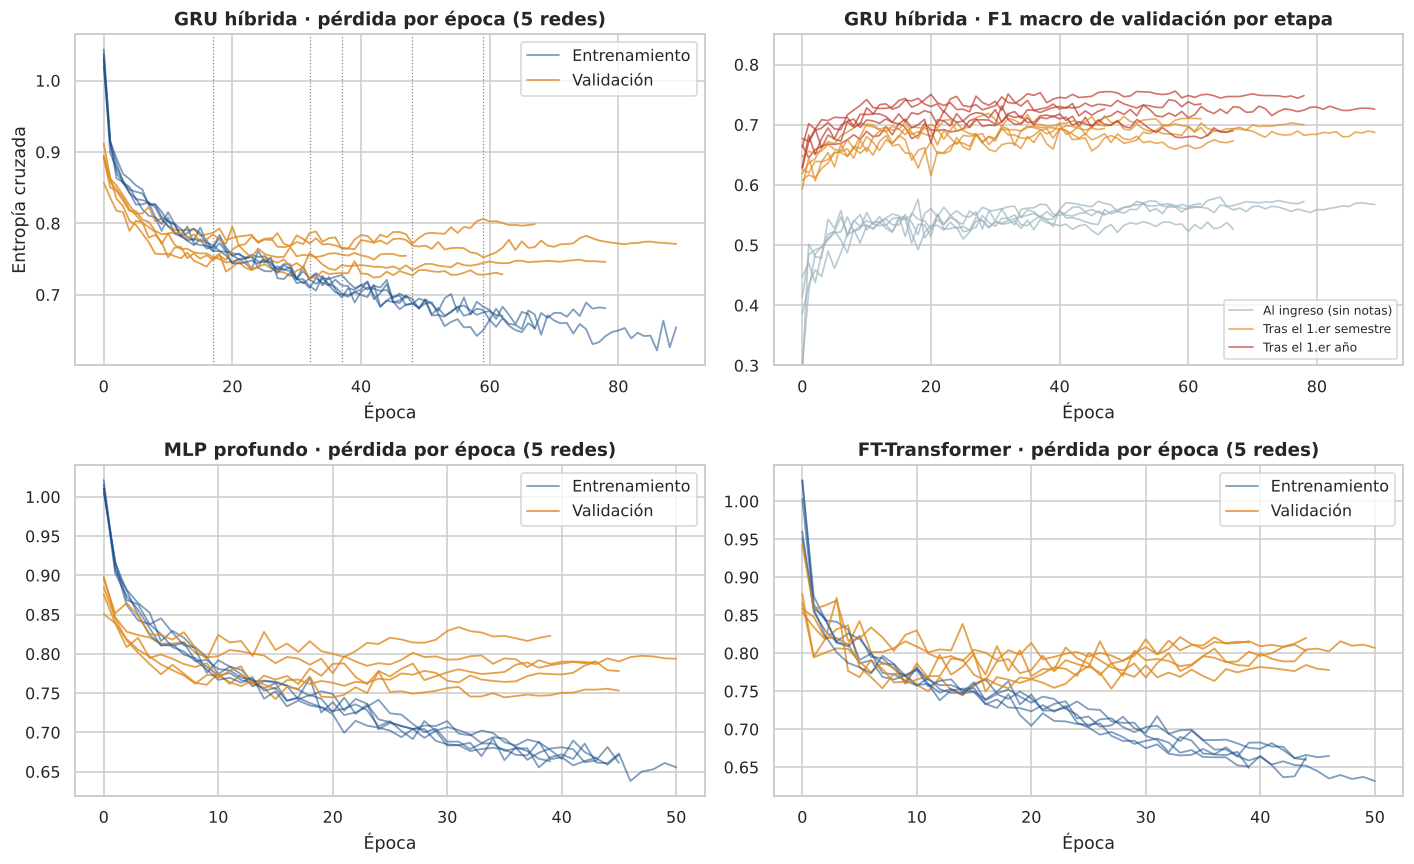

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
for i, h in enumerate(historiales["rnn"]):
    ax.plot(h["perdida_entrenamiento"], color="#1A4F8B", alpha=.55, lw=1.2, label="Entrenamiento" if i == 0 else None)
    ax.plot(h["perdida_validacion"], color="#E08A1E", alpha=.8, lw=1.2, label="Validación" if i == 0 else None)
    ax.axvline(h["mejor_epoca"] - 1, color="gray", ls=":", lw=.8)
ax.set_title("GRU híbrida · pérdida por época (5 redes)"); ax.set_xlabel("Época"); ax.set_ylabel("Entropía cruzada"); ax.legend()

ax = axes[0, 1]
for i, h in enumerate(historiales["rnn"]):
    f = np.array(h["f1_validacion_por_etapa"])
    for e, col in zip((0, 1, 2), ("#9DB4C0", "#E08A1E", "#C0392B")):
        ax.plot(f[:, e], color=col, alpha=.7, lw=1.1, label=ETAPAS[e] if i == 0 else None)
ax.set_title("GRU híbrida · F1 macro de validación por etapa"); ax.set_xlabel("Época"); ax.set_ylim(0.3, 0.85); ax.legend(fontsize=8)

for ax, nombre in zip(axes[1], ("mlp", "ftt")):
    for i, h in enumerate(historiales[nombre]):
        ax.plot(h["perdida_entrenamiento"], color="#1A4F8B", alpha=.55, lw=1.2, label="Entrenamiento" if i == 0 else None)
        ax.plot(h["perdida_validacion"], color="#E08A1E", alpha=.8, lw=1.2, label="Validación" if i == 0 else None)
    ax.set_title(f"{NOMBRE[nombre]} · pérdida por época (5 redes)"); ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.savefig(FIGS / "02_curvas_entrenamiento.png", dpi=200, bbox_inches="tight"); plt.show()

Las curvas muestran un entrenamiento sano. Durante las primeras 20 a 40 épocas la pérdida de validación baja junto con la de entrenamiento; después se estabiliza mientras la de entrenamiento sigue bajando. Ese es el punto donde empieza el sobreajuste, y la parada temprana recupera los pesos de la mejor época (líneas punteadas, entre la 18 y la 60 según la red). Al principio la pérdida de entrenamiento queda por encima de la de validación porque incluye el suavizado de etiquetas y el aumento de datos. El panel derecho muestra el precio de alertar temprano: el F1 de validación se estabiliza cerca de 0,55 al ingreso, de 0,69 tras S1 y de 0,73 tras el año. El MLP y el FT-Transformer alcanzan su mejor punto antes (épocas 10 a 21) y la brecha entre sus curvas crece más rápido.

---
## Paso 4 · Evaluación en el conjunto de prueba
Los 885 estudiantes de prueba se usan ahora por primera vez. Son los mismos del ACA 1, así que las cifras de la regresión logística son directamente comparables.

In [17]:
t_te = {e: en.codificar_por_etapa(cod_final, te, e) for e in (0, 1, 2)}
proba = {n: {e: en.predecir(ensambles[n], t_te[e]) for e in (0, 1, 2)} for n in ensambles}
proba["lr"] = {e: lb.pipeline_aca1(e, SEED).fit(tr, y_tr).predict_proba(te) for e in (0, 1, 2)}

filas = []
for n in ("rnn", "mlp", "ftt", "lr"):
    for e in (0, 1, 2):
        m = en.metricas(y_te, proba[n][e])
        filas.append({"modelo": NOMBRE[n], "etapa": ETAPAS[e], **{k: m[k] for k in
                      ("Exactitud", "F1 macro", "Sensibilidad Deserción", "ROC-AUC (OvR macro)", "Log-loss")}})
prueba = pd.DataFrame(filas)
display(prueba.pivot(index="modelo", columns="etapa", values="F1 macro")[list(ETAPAS.values())]
        .reindex([NOMBRE[n] for n in ("rnn", "mlp", "ftt", "lr")]).round(3))
prueba[prueba.etapa == ETAPAS[2]].set_index("modelo").drop(columns="etapa").round(3)

etapa,Al ingreso (sin notas),Tras el 1.er semestre,Tras el 1.er año
modelo,,,
GRU híbrida,0.547,0.665,0.704
MLP profundo,0.533,0.668,0.697
FT-Transformer,0.557,0.680,0.701
Regresión logística (ACA 1),0.560,0.655,0.691


,Exactitud,F1 macro,Sensibilidad Deserción,ROC-AUC (OvR macro),Log-loss
modelo,,,,,
GRU híbrida,0.754,0.704,0.711,0.877,0.604
MLP profundo,0.746,0.697,0.680,0.871,0.631
FT-Transformer,0.746,0.701,0.694,0.881,0.625
Regresión logística (ACA 1),0.740,0.691,0.701,0.874,0.622


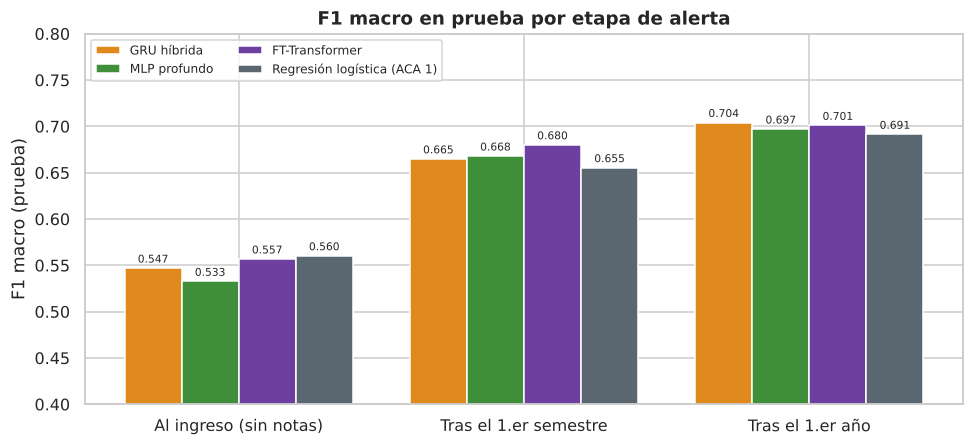

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(3); w = 0.2
for i, n in enumerate(("rnn", "mlp", "ftt", "lr")):
    v = [f1_score(y_te, proba[n][e].argmax(1), average="macro") for e in (0, 1, 2)]
    b = ax.bar(x + (i - 1.5) * w, v, w, label=NOMBRE[n], color=COLOR_MODELO[NOMBRE[n]])
    ax.bar_label(b, fmt="%.3f", fontsize=7, padding=2)
ax.set_xticks(x, list(ETAPAS.values())); ax.set_ylim(0.4, 0.8); ax.set_ylabel("F1 macro (prueba)")
ax.set_title("F1 macro en prueba por etapa de alerta"); ax.legend(ncol=2, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "03_f1_por_etapa.png", dpi=200, bbox_inches="tight"); plt.show()

En los 885 estudiantes de prueba la **GRU híbrida logra el mejor F1 macro tras el año (0,704)** y la mejor exactitud (75,4 %), por encima de la regresión del ACA 1 (0,691 y 74,0 %). Tras el primer semestre también supera a la regresión (0,665 frente a 0,655), aunque en esa etapa el mejor es el FT-Transformer (0,680), que además tiene el ROC-AUC más alto tras el año (0,881). Al ingreso la regresión conserva una ligera ventaja (0,560 frente a 0,547 de la GRU). La GRU también tiene la menor log-loss (0,604), es decir, las probabilidades mejor calibradas de los cuatro modelos, algo que importa en una app que muestra probabilidades.

In [19]:
PRINCIPAL = "rnn"
p_main = proba[PRINCIPAL][2]
met_main = en.metricas(y_te, p_main)
ic_main = en.bootstrap_ic(y_te, p_main, n=1000, semilla=SEED)
diferencias = {ETAPAS[e]: en.bootstrap_diferencia(y_te, proba[PRINCIPAL][e], proba["lr"][e], n=2000, semilla=SEED)
               for e in (0, 1, 2)}
display(pd.DataFrame({"valor": met_main}).assign(**{"IC 95 %": [
    f"[{ic_main[k][0]:.3f} – {ic_main[k][1]:.3f}]" if k in ic_main else "" for k in met_main]}).round(3))
pd.DataFrame({k: {"diferencia F1 (GRU − LR)": v["diferencia"], "IC 95 % inferior": v["ic95"][0],
                  "IC 95 % superior": v["ic95"][1], "P(GRU mejor)": v["p_a_mejor"]}
              for k, v in diferencias.items()}).T.round(3)

,valor,IC 95 %
Exactitud,0.754,[0.727 – 0.783]
Exactitud balanceada,0.706,
F1 macro,0.704,[0.674 – 0.738]
F1 ponderado,0.760,
Precisión macro,0.710,
Sensibilidad macro,0.706,
Sensibilidad Deserción,0.711,
ROC-AUC (OvR macro),0.877,[0.857 – 0.896]
Kappa de Cohen,0.603,
MCC,0.605,


,diferencia F1 (GRU − LR),IC 95 % inferior,IC 95 % superior,P(GRU mejor)
Al ingreso (sin notas),-0.013,-0.038,0.010,0.136
Tras el 1.er semestre,0.009,-0.014,0.032,0.766
Tras el 1.er año,0.013,-0.006,0.031,0.906


El *bootstrap* pareado (2.000 réplicas del mismo conjunto de prueba) pone las cifras en perspectiva. Tras el año la GRU supera a la regresión en 0,013 de F1, con un intervalo de confianza de −0,006 a 0,031. La ventaja aparece en el 90,6 % de las réplicas, pero el intervalo incluye el cero, así que la diferencia no es estadísticamente concluyente. Tras S1 pasa algo parecido (+0,009, a favor de la GRU en el 76,6 % de las réplicas) y al ingreso la regresión va adelante (−0,013). La lectura honesta es que la GRU **iguala o supera ligeramente** a la línea base, y lo hace con un solo modelo para las tres etapas.

              precision    recall  f1-score   support

   Deserción      0.845     0.711     0.772       284
 Matriculado      0.442     0.553     0.492       159
    Graduado      0.843     0.853     0.848       442

    accuracy                          0.754       885
   macro avg      0.710     0.706     0.704       885
weighted avg      0.772     0.754     0.760       885



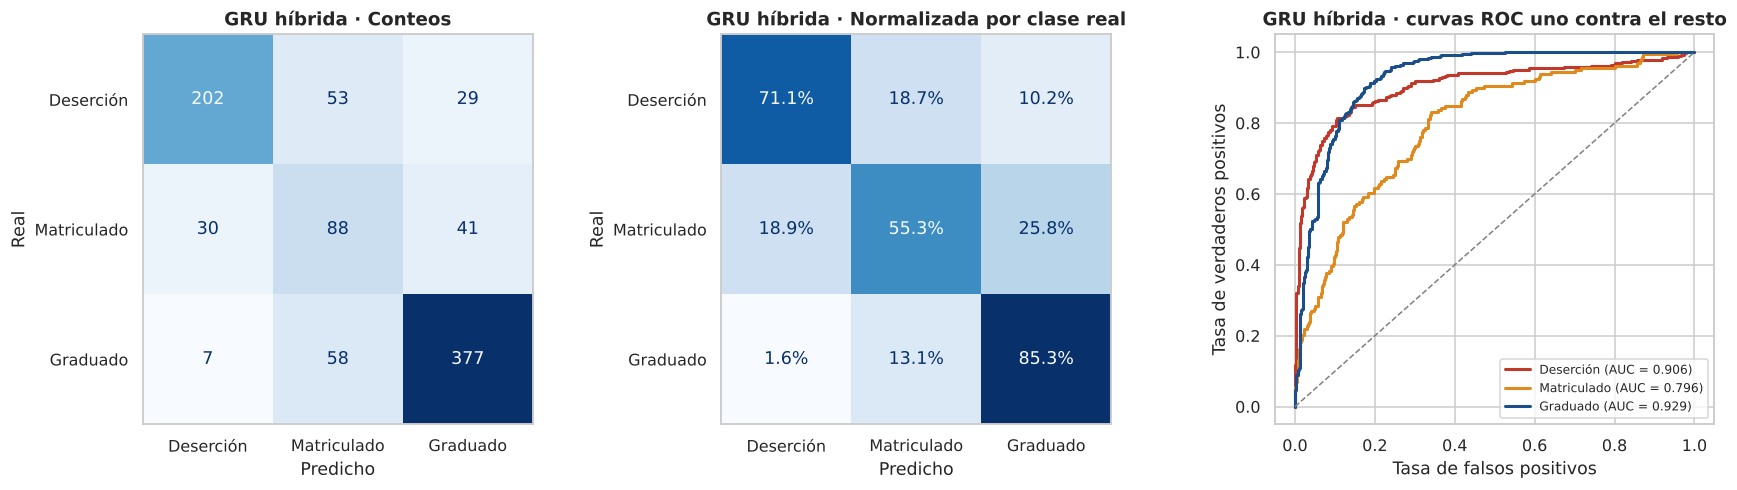

In [20]:
pred_main = p_main.argmax(1)
print(classification_report(y_te, pred_main, target_names=CLASES, digits=3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, norm, t in [(axes[0], None, "Conteos"), (axes[1], "true", "Normalizada por clase real")]:
    ConfusionMatrixDisplay.from_predictions(y_te, pred_main, display_labels=CLASES, normalize=norm, cmap="Blues",
                                            values_format=".0f" if norm is None else ".1%", ax=ax, colorbar=False)
    ax.set_title(f"GRU híbrida · {t}"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
for k, c in enumerate(CLASES):
    fpr, tpr, _ = roc_curve((y_te == k).astype(int), p_main[:, k])
    axes[2].plot(fpr, tpr, lw=2, color=COLORES[c], label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
axes[2].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axes[2].set_title("GRU híbrida · curvas ROC uno contra el resto"); axes[2].set_xlabel("Tasa de falsos positivos")
axes[2].set_ylabel("Tasa de verdaderos positivos"); axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "04_confusion_roc.png", dpi=200, bbox_inches="tight"); plt.show()
cm_main = confusion_matrix(y_te, pred_main)

La GRU detecta al **71,1 % de quienes desertaron** (202 de 284) y, cuando da la alerta de deserción, acierta el 84,5 % de las veces. El error más grave para una institución, confundir a un desertor con un graduado, ocurre en 29 casos (10,2 %), y solo 7 graduados (1,6 %) reciben una alerta de deserción. *Matriculado* sigue siendo la clase difícil (F1 de 0,492, frente a 0,474 en el ACA 1): son estudiantes atrasados que todavía no se van y se confunden hacia ambos lados. Las curvas ROC confirman ese orden: el modelo separa muy bien a graduados (AUC 0,929) y desertores (0,906), y bastante peor a los matriculados (0,796).

### 4.1 ¿Qué mira la red? Importancia por permutación
Se desordena un grupo de variables a la vez en el conjunto de prueba (por ejemplo, las seis del 2.º semestre juntas) y se mide cuánto cae el F1 macro de la GRU tras el año. Agrupar evita subestimar variables muy correlacionadas entre sí y deja la lectura en términos que entiende un coordinador académico.

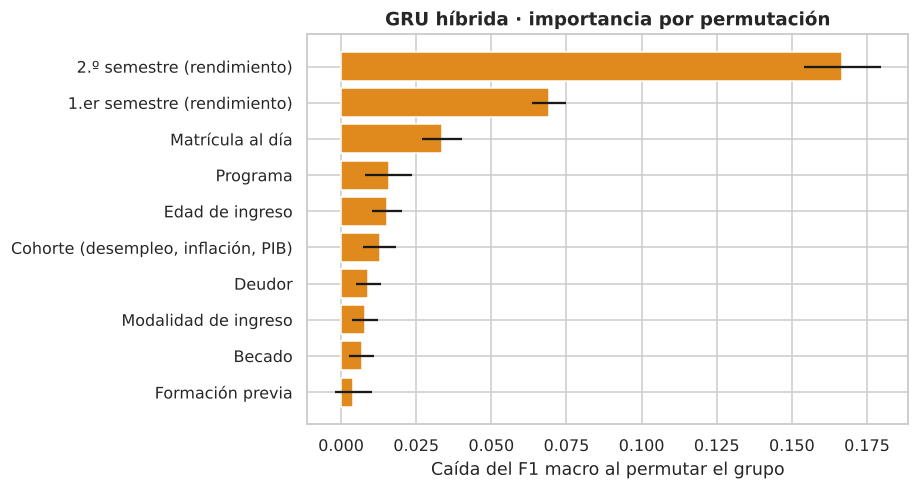

,grupo,caida_f1,desv
0,2.º semestre (rendimiento),0.167,0.013
1,1.er semestre (rendimiento),0.069,0.006
2,Matrícula al día,0.034,0.007
3,Programa,0.016,0.008
4,Edad de ingreso,0.015,0.005
5,"Cohorte (desempleo, inflación, PIB)",0.013,0.005
6,Deudor,0.009,0.004
7,Modalidad de ingreso,0.008,0.004
8,Becado,0.007,0.004
9,Formación previa,0.004,0.006


In [21]:
GRUPOS = {
    "2.º semestre (rendimiento)": [c for c in te.columns if c.startswith("s2_")],
    "1.er semestre (rendimiento)": [c for c in te.columns if c.startswith("s1_")],
    "Matrícula al día": ["matricula_al_dia"], "Deudor": ["deudor"], "Becado": ["becado"],
    "Programa": ["programa"], "Edad de ingreso": ["edad_ingreso"], "Modalidad de ingreso": ["modo_ingreso"],
    "Nota de admisión": ["nota_admision"], "Formación previa": ["formacion_previa", "nota_formacion_previa"],
    "Género": ["genero_masculino"], "Estado civil": ["estado_civil"],
    "Familia (educación y ocupación de los padres)": ["educacion_madre", "educacion_padre", "ocupacion_madre", "ocupacion_padre"],
    "Cohorte (desempleo, inflación, PIB)": ["tasa_desempleo", "tasa_inflacion", "pib"],
    "Otros (jornada, desplazado, NEE, internacional, orden)": ["jornada_diurna", "desplazado", "necesidades_especiales",
                                                               "internacional", "orden_opcion"],
}
base_f1 = f1_score(y_te, p_main.argmax(1), average="macro")
rng = np.random.default_rng(SEED)
imp = []
for g, cols in GRUPOS.items():
    caidas = []
    for _ in range(10):
        perm = te.copy()
        idx = rng.permutation(len(te))
        perm[cols] = te[cols].to_numpy()[idx]
        p = en.predecir(ensambles[PRINCIPAL], en.codificar_por_etapa(cod_final, perm, 2))
        caidas.append(base_f1 - f1_score(y_te, p.argmax(1), average="macro"))
    imp.append({"grupo": g, "caida_f1": np.mean(caidas), "desv": np.std(caidas)})
importancia = pd.DataFrame(imp).sort_values("caida_f1", ascending=False).reset_index(drop=True)
top = importancia.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(top["grupo"], top["caida_f1"], xerr=top["desv"], color="#E08A1E")
ax.set_xlabel("Caída del F1 macro al permutar el grupo"); ax.set_title("GRU híbrida · importancia por permutación")
plt.tight_layout(); plt.savefig(FIGS / "05_importancia.png", dpi=200, bbox_inches="tight"); plt.show()
importancia.round(4)

La red mira lo mismo que mostró el análisis exploratorio. Si se desordena el rendimiento del 2.º semestre, el F1 cae 0,167; con el del 1.er semestre, 0,069. Siguen la matrícula al día (0,034), el programa (0,016), la edad de ingreso (0,015) y la cohorte (0,013). La nota de admisión, el género y la familia casi no pesan. El componente recurrente se apoya, como se esperaba, en la trayectoria, y el contexto de ingreso aporta sobre todo por el lado financiero.

---
## Paso 5 · Exportación para la app de Streamlit
PyTorch pesa cerca de 1 GB instalado, demasiado para una app gratuita en Streamlit Community Cloud. Por eso cada ensamble se exporta a **ONNX**, un formato abierto que se ejecuta con `onnxruntime` (unos 15 MB). La app solo necesita:

- `modelo/red_gru.onnx` (y `red_mlp.onnx`, `red_ftt.onnx` para comparar en la interfaz);
- `modelo/codificador.json` con las estadísticas del entrenamiento;
- `modelo/metadatos.json` con las métricas, las curvas y los ejemplos que muestra la app;
- `nucleo/codificador.py` y `nucleo/preprocesamiento.py`, que solo dependen de numpy y pandas.

Después de exportar se comprueba que onnxruntime y PyTorch den las mismas probabilidades.

In [22]:
import onnxruntime as ort

ARCHIVO = {"rnn": "red_gru.onnx", "mlp": "red_mlp.onnx", "ftt": "red_ftt.onnx"}
ENTRADAS = ["cat", "est", "seq", "mask"]
verificacion = {}
for n, ens in ensambles.items():
    ruta = MODELO / ARCHIVO[n]
    ej = en.codificar_por_etapa(cod_final, te.iloc[:8], 2)
    torch.onnx.export(ens, tuple(ej[k] for k in ENTRADAS), str(ruta), input_names=ENTRADAS,
                      output_names=["probabilidades"], opset_version=17, dynamo=False,
                      dynamic_axes={k: {0: "n"} for k in ENTRADAS + ["probabilidades"]})
    sesion = ort.InferenceSession(str(ruta), providers=["CPUExecutionProvider"])
    dif = max(np.abs(sesion.run(None, {k: cod_final.transformar(te, e)[k] for k in ENTRADAS})[0] - proba[n][e]).max()
              for e in (0, 1, 2))
    verificacion[NOMBRE[n]] = {"archivo": ARCHIVO[n], "tamaño (KB)": ruta.stat().st_size / 1024,
                               "máx. diferencia ONNX vs PyTorch": f"{dif:.1e}"}
cod_final.guardar(MODELO / "codificador.json")
pd.DataFrame(verificacion).T

,archivo,tamaño (KB),máx. diferencia ONNX vs PyTorch
GRU híbrida,red_gru.onnx,"1,181.551",1.8e-07
MLP profundo,red_mlp.onnx,"1,281.127",1.8e-07
FT-Transformer,red_ftt.onnx,562.388,1.8e-07


In [23]:
# Perfil de referencia (estudiante "típico" del entrenamiento) para las explicaciones de la app
referencia = {}
for c in tr.columns:
    if c in ("estudiante_id", "resultado", "particion", "cohorte_id"):
        continue
    v = tr[c]
    if c in cdf.NUMERICAS or c.startswith(("s1_", "s2_")):
        referencia[c] = float(v[tr["sin_registro_curricular"] == 0].median()) if c.startswith(("s1_", "s2_")) else float(v.median())
    else:
        referencia[c] = float(v.mode().iloc[0])

# Casos de ejemplo reales del conjunto de prueba (riesgo alto, medio y bajo según la GRU)
# (solo estudiantes con registro curricular, para que la app los reproduzca tal cual)
p_des = pd.Series(proba[PRINCIPAL][2][:, 0], index=te.index)[te["sin_registro_curricular"] == 0]
casos = {"Riesgo alto": int(te.loc[p_des.sort_values(ascending=False).index[5], "estudiante_id"]),
         "Riesgo medio": int(te.loc[(p_des - 0.45).abs().sort_values().index[0], "estudiante_id"]),
         "Riesgo bajo": int(te.loc[p_des.sort_values().index[5], "estudiante_id"])}

def r4(x):
    return float(round(float(x), 4))

historial_app = {NOMBRE[n]: [{k: [r4(v) for v in h[k]] for k in ("perdida_entrenamiento", "perdida_validacion",
                                                           "f1_validacion")} | {"mejor_epoca": h["mejor_epoca"]}
                     for h in historiales[n]] for n in historiales}
metadatos = {
    "proyecto": "ACA 2 · Aprendizaje Automático · CUN · Grupo 7",
    "modelo_principal": NOMBRE[PRINCIPAL],
    "clases": CLASES, "etapas": {str(k): v for k, v in ETAPAS.items()},
    "archivos": {NOMBRE[n]: ARCHIVO[n] for n in ARCHIVO},
    "hiperparametros": {NOMBRE[n]: {k: (list(v) if isinstance(v, tuple) else v) for k, v in mejores[n]["hp"].items()}
                        for n in ("rnn", "mlp", "ftt")},
    "parametros": {NOMBRE[n]: redes.contar_parametros(ensambles[n].modelos[0]) for n in ensambles},
    "n_train": int(len(tr)), "n_test": int(len(te)),
    "versiones": {"torch": torch.__version__, "onnxruntime": ort.__version__, "sklearn": sklearn.__version__},
    "validacion_cruzada": comp_cv.reset_index().round(4).to_dict(orient="records"),
    "busqueda": busqueda.round(4).to_dict(orient="records"),
    "ablacion": ablacion.reset_index().round(4).to_dict(orient="records"),
    "prueba": prueba.round(4).to_dict(orient="records"),
    "metricas_principal": {k: r4(v) for k, v in met_main.items()},
    "ic95_principal": {k: [r4(a) for a in v] for k, v in ic_main.items()},
    "diferencia_vs_lr": {k: {"diferencia": r4(v["diferencia"]), "ic95": [r4(a) for a in v["ic95"]],
                             "p_mejor": r4(v["p_a_mejor"])} for k, v in diferencias.items()},
    "por_clase": {c: {m: r4(v) for m, v in d.items()} for c, d in
                  classification_report(y_te, pred_main, target_names=CLASES, output_dict=True).items() if c in CLASES},
    "matrices_confusion": {NOMBRE[n]: {ETAPAS[e]: confusion_matrix(y_te, proba[n][e].argmax(1)).tolist() for e in (0, 1, 2)}
                           for n in proba},
    "importancia": importancia.round(4).to_dict(orient="records"),
    "curvas": historial_app,
    "referencia": referencia,
    "casos_ejemplo": casos,
}
(MODELO / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=1), encoding="utf-8")

# Archivo de ejemplo para la carga por lotes en la app (30 estudiantes de prueba, sin el resultado)
cols_lote = ["estudiante_id"] + [c for c in te.columns if c not in ("resultado", "particion", "cohorte_id")
                                  and c != "estudiante_id"]
te.sample(30, random_state=SEED)[cols_lote].to_csv(MODELO / "ejemplo_lote.csv", index=False)
for f in sorted(MODELO.iterdir()):
    print(f"{f.name:<22} {f.stat().st_size / 1024:8.1f} KB")

codificador.json            3.3 KB
ejemplo_lote.csv            4.7 KB
metadatos.json             47.0 KB
red_ftt.onnx              562.4 KB
red_gru.onnx             1181.6 KB
red_mlp.onnx             1281.1 KB


In [24]:
# Prueba de humo: recargar desde disco y predecir un estudiante como lo hará la app
cod_app = cdf.CodificadorTabular.cargar(MODELO / "codificador.json")
sesion = ort.InferenceSession(str(MODELO / "red_gru.onnx"), providers=["CPUExecutionProvider"])
caso = te[te.estudiante_id == casos["Riesgo alto"]]
print("Resultado real:", caso["resultado"].iloc[0])
for e, desc in ETAPAS.items():
    p = sesion.run(None, {k: v for k, v in cod_app.transformar(caso, e).items()})[0][0]
    print(f"  {desc:<24}", {c: round(float(v), 3) for c, v in zip(CLASES, p)})

Resultado real: Deserción
  Al ingreso (sin notas)   {'Deserción': 0.584, 'Matriculado': 0.279, 'Graduado': 0.137}
  Tras el 1.er semestre    {'Deserción': 0.968, 'Matriculado': 0.024, 'Graduado': 0.008}
  Tras el 1.er año         {'Deserción': 0.97, 'Matriculado': 0.023, 'Graduado': 0.007}


La prueba de humo reproduce el uso de la app con un estudiante real del conjunto de prueba que desertó. Al ingreso la red ya le asigna 58 % de probabilidad de deserción; cuando ve su primer semestre la cifra sube a 97 % y se mantiene tras el año. Es el comportamiento que se busca en una alerta temprana: con poca información el modelo es prudente y gana seguridad a medida que llegan los datos.

---
## 6. Conclusiones

- **Respuesta a la pregunta orientadora.** Una GRU híbrida que lee la trayectoria semestre a semestre clasifica a 885 estudiantes nunca vistos con 75,4 % de exactitud, F1 macro de 0,704 (IC 95 %: 0,674–0,738) y ROC-AUC de 0,877, y detecta al 71,1 % de quienes desertan. La app de Streamlit pone esa predicción, su evolución por etapa y una explicación de los factores al alcance de un consejero académico.
- **Un modelo, tres momentos de alerta.** El enmascaramiento de trayectoria permitió reemplazar los tres modelos del ACA 1 por una sola red. Sin esa técnica, el F1 de la alerta al ingreso caía de 0,544 a 0,441.
- **Las redes igualan a la regresión logística; no la superan con claridad.** En validación cruzada hubo empate técnico (0,720 frente a 0,723) y en prueba la GRU quedó adelante por 0,013, sin significancia estadística. Con 4.424 registros tabulares es lo esperable. El valor de la red está en la representación secuencial, en probabilidades mejor calibradas (log-loss de 0,604) y en la flexibilidad del despliegue.
- **SQL como columna vertebral.** Guardar la trayectoria en formato largo hizo natural construir las secuencias y permitió análisis como el *self-join* entre semestres, que mostró que el 13,5 % de los desertores pasa de aprobar algo a no aprobar nada.
- **Despliegue liviano.** Al exportar los ensambles a ONNX la app no depende de PyTorch, y las probabilidades coinciden con las del notebook (diferencias menores a 10⁻⁶).
- **Limitaciones y trabajo futuro.** Los datos son de una sola institución portuguesa, la clase *Matriculado* sigue siendo difícil y el modelo usa variables sensibles como el género y la edad. Antes de llevarlo a una institución colombiana habría que reentrenarlo con datos propios, extender la secuencia a más semestres (ahí una red recurrente o un Transformer temporal sí tendrían más margen de ventaja) y auditar posibles sesgos, en cumplimiento de la Ley 1581 de 2012.

## Referencias

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734). Association for Computational Linguistics. https://doi.org/10.3115/v1/D14-1179

Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *Advances in Neural Information Processing Systems, 34*, 18932–18943.

Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35*, 507–520.

Guo, C., & Berkhahn, F. (2016). *Entity embeddings of categorical variables* (arXiv:1604.06737). arXiv. https://doi.org/10.48550/arXiv.1604.06737

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Laboratorio de Economía de la Educación. (2023). *Deserción en la educación superior en Colombia* (Informe de análisis estadístico n.º 74). Pontificia Universidad Javeriana.

Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. En *International Conference on Learning Representations (ICLR 2019)*. https://openreview.net/forum?id=Bkg6RiCqY7

ONNX Runtime developers. (2021). *ONNX Runtime* [Software]. https://onnxruntime.ai/

Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*, 8024–8035.

Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data, 7*(11), Artículo 146. https://doi.org/10.3390/data7110146

Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89

Streamlit Inc. (2024). *Streamlit documentation*. https://docs.streamlit.io/

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*, 5998–6008.